In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
basepath = '/content/drive/Shareddrives/ECEN_649_PR_Project/SVM/glcm_features'

In [ ]:
df = pd.read_csv(basepath + '/glcm_features_0deg.csv')
df.drop(columns='file_name', inplace=True)
from sklearn.preprocessing import PowerTransformer
transformer = PowerTransformer(method='yeo-johnson')
df = pd.DataFrame(transformer.fit_transform(df))

df.head()

/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:176: RuntimeWarning: overflow encountered in multiply
  x = um.multiply(x, x, out=x)
/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:187: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


,0,1,2,3,4,5,6,7,8
0,-0.010650,-1.591592,0.490285,-1.159057,-1.124810,0.874476,1.019416,-1.117746,1.027989
1,-2.869528,-0.942222,1.970410,-0.374288,-0.368489,1.888774,0.432438,-0.369636,0.398736
2,-1.429454,-0.611416,1.330153,-0.128282,-0.132933,1.275551,0.143479,-0.133683,0.149403
3,-0.284823,-0.075011,0.573136,0.508733,0.484656,0.490415,-0.481963,0.483203,-0.478421
4,0.432841,1.934448,-0.705607,2.102164,2.162704,-1.218014,-2.140244,2.170213,-2.145341


In [ ]:
tags = pd.read_csv(basepath + '/tag.csv')
labels = tags['pathology']
df.head()

,0,1,2,3,4,5,6,7,8
0,-0.010650,-1.591592,0.490285,-1.159057,-1.124810,0.874476,1.019416,-1.117746,1.027989
1,-2.869528,-0.942222,1.970410,-0.374288,-0.368489,1.888774,0.432438,-0.369636,0.398736
2,-1.429454,-0.611416,1.330153,-0.128282,-0.132933,1.275551,0.143479,-0.133683,0.149403
3,-0.284823,-0.075011,0.573136,0.508733,0.484656,0.490415,-0.481963,0.483203,-0.478421
4,0.432841,1.934448,-0.705607,2.102164,2.162704,-1.218014,-2.140244,2.170213,-2.145341


In [ ]:
labels.head()

,pathology
0,MALIGNANT
1,BENIGN
2,BENIGN
3,MALIGNANT
4,MALIGNANT


In [ ]:
x = 'BENIGN_WITHOUT_CALLBACK'
indices = labels.index[labels == x].tolist()
print(indices)
labels = labels.drop(index=indices)
df = df.drop(index=indices)

[5, 7, 16, 29, 43, 47, 59, 61, 62, 63, 65, 74, 75, 76, 79, 81, 85, 87, 89, 90, 91, 93, 97, 115, 118, 119, 120, 137, 139, 140, 145, 159, 161, 169, 176, 181, 190, 194, 195, 197, 202, 203, 209, 212, 214, 221, 229, 230, 236, 237, 244, 247, 266, 270, 279, 281, 286, 288, 293, 300, 302, 310, 312, 320, 325, 328, 332, 335, 350, 363, 372, 380, 386, 394, 403, 410, 424, 431, 438, 439, 445, 449, 457, 462, 466, 476, 477, 481, 488, 494, 497, 505, 507, 513, 514, 537, 540, 545, 550, 559, 563, 567, 576, 580, 581, 584, 586, 592, 599, 603, 619, 620, 623, 636, 637, 640, 648, 652, 661, 665, 666, 672, 674, 687, 688, 690, 697, 707, 719, 726, 732, 741, 743, 746, 749, 752, 755, 757, 763, 773, 780, 782, 788, 790, 792, 793, 794, 798, 799, 820, 821, 836, 842, 844, 847, 850, 860, 874, 876, 889, 890, 897, 900, 904, 911, 912, 918, 921, 922, 929, 931, 942, 943, 944, 946, 948, 955, 965, 968, 971, 974, 976, 978, 981, 984, 986, 999, 1002, 1010, 1017, 1021, 1024, 1031, 1034, 1035, 1041, 1042, 1050, 1055, 1056, 1062, 1065,

In [ ]:
labels_encoded = labels.replace({'BENIGN': 0, 'MALIGNANT': 1})

<ipython-input-157-0ffeb7f19508>:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  labels_encoded = labels.replace({'BENIGN': 0, 'MALIGNANT': 1})


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df, labels_encoded, test_size=0.2, random_state=42)

In [ ]:
clf = SVC(kernel='rbf', gamma=0.111, C=1.0)
clf.fit(X_train, y_train)

SVC(gamma=0.111)

In [ ]:
y_pred = clf.predict(X_test)

In [ ]:
print(classification_report(y_test, y_pred))
clf_rep135 = classification_report(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.53      0.66      0.59        92
           1       0.62      0.48      0.54       106

    accuracy                           0.57       198
   macro avg       0.57      0.57      0.56       198
weighted avg       0.58      0.57      0.56       198



In [ ]:
scores_135deg = cross_val_score(clf, df, labels, cv=50)
scores_135deg

array([0.6       , 0.6       , 0.55      , 0.6       , 0.7       ,
       0.65      , 0.35      , 0.5       , 0.4       , 0.35      ,
       0.6       , 0.5       , 0.5       , 0.55      , 0.5       ,
       0.5       , 0.55      , 0.65      , 0.65      , 0.5       ,
       0.6       , 0.65      , 0.65      , 0.5       , 0.35      ,
       0.6       , 0.35      , 0.55      , 0.7       , 0.5       ,
       0.5       , 0.55      , 0.55      , 0.6       , 0.5       ,
       0.65      , 0.4       , 0.5       , 0.5       , 0.52631579,
       0.31578947, 0.73684211, 0.63157895, 0.47368421, 0.63157895,
       0.57894737, 0.47368421, 0.63157895, 0.57894737, 0.63157895])

In [ ]:
print(classification_report(y_test, y_pred))
clf_rep90 = classification_report(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.49      0.59      0.53        92
           1       0.56      0.46      0.51       106

    accuracy                           0.52       198
   macro avg       0.52      0.52      0.52       198
weighted avg       0.53      0.52      0.52       198



In [ ]:
scores_90deg = cross_val_score(clf, df, labels, cv=50)
scores_90deg

array([0.6       , 0.65      , 0.5       , 0.45      , 0.65      ,
       0.6       , 0.35      , 0.4       , 0.45      , 0.35      ,
       0.6       , 0.6       , 0.4       , 0.5       , 0.5       ,
       0.5       , 0.5       , 0.6       , 0.5       , 0.55      ,
       0.5       , 0.65      , 0.7       , 0.45      , 0.35      ,
       0.6       , 0.4       , 0.55      , 0.7       , 0.5       ,
       0.45      , 0.55      , 0.35      , 0.45      , 0.4       ,
       0.6       , 0.4       , 0.45      , 0.45      , 0.52631579,
       0.31578947, 0.63157895, 0.68421053, 0.42105263, 0.63157895,
       0.52631579, 0.31578947, 0.63157895, 0.63157895, 0.57894737])

In [ ]:
print(classification_report(y_test, y_pred))
clf_rep45 = classification_report(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.52      0.67      0.58        92
           1       0.62      0.45      0.52       106

    accuracy                           0.56       198
   macro avg       0.57      0.56      0.55       198
weighted avg       0.57      0.56      0.55       198



In [ ]:
scores_45deg = cross_val_score(clf, df, labels, cv=50)
scores_45deg

array([0.55      , 0.6       , 0.55      , 0.55      , 0.65      ,
       0.6       , 0.35      , 0.55      , 0.4       , 0.35      ,
       0.55      , 0.5       , 0.5       , 0.6       , 0.5       ,
       0.5       , 0.5       , 0.7       , 0.65      , 0.5       ,
       0.55      , 0.6       , 0.65      , 0.5       , 0.4       ,
       0.6       , 0.3       , 0.6       , 0.7       , 0.55      ,
       0.55      , 0.55      , 0.5       , 0.6       , 0.45      ,
       0.65      , 0.45      , 0.5       , 0.5       , 0.52631579,
       0.26315789, 0.73684211, 0.63157895, 0.47368421, 0.63157895,
       0.52631579, 0.42105263, 0.63157895, 0.63157895, 0.68421053])

In [ ]:
print(classification_report(y_test, y_pred))
clf_rep0 = classification_report(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.52      0.66      0.58        92
           1       0.62      0.47      0.53       106

    accuracy                           0.56       198
   macro avg       0.57      0.57      0.56       198
weighted avg       0.57      0.56      0.56       198



In [ ]:
scores_0deg = cross_val_score(clf, df, labels, cv=50)
scores_0deg

array([0.55      , 0.6       , 0.55      , 0.55      , 0.65      ,
       0.6       , 0.4       , 0.5       , 0.4       , 0.4       ,
       0.55      , 0.5       , 0.5       , 0.65      , 0.5       ,
       0.45      , 0.65      , 0.65      , 0.6       , 0.55      ,
       0.65      , 0.6       , 0.7       , 0.55      , 0.45      ,
       0.6       , 0.4       , 0.6       , 0.7       , 0.5       ,
       0.5       , 0.5       , 0.55      , 0.65      , 0.6       ,
       0.55      , 0.5       , 0.55      , 0.5       , 0.57894737,
       0.42105263, 0.73684211, 0.68421053, 0.52631579, 0.63157895,
       0.52631579, 0.47368421, 0.68421053, 0.63157895, 0.78947368])

In [ ]:
bestscores = [max(scores_0deg), max(scores_45deg), max(scores_90deg), max(scores_135deg)]

In [ ]:
bestscores

[0.7894736842105263, 0.7368421052631579, 0.7, 0.7368421052631579]

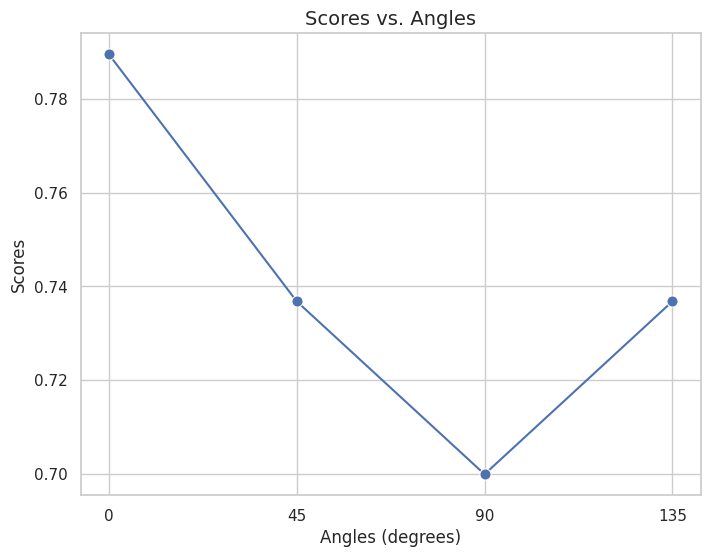

In [ ]:
# Data
angles = [0, 45, 90, 135]

# Create the plot
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.lineplot(x=angles, y=bestscores, marker="o", markersize=8)

# Add labels and title
plt.title("Scores vs. Angles", fontsize=14)
plt.xlabel("Angles (degrees)", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.xticks(angles)  # Ensure all points are labeled on the x-axis
plt.grid(True)

# Show the plot
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(n_estimators=1500, criterion='gini', random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred = rf_classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
accuracy

0.5117845117845118

In [ ]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    verbosity=1,
)

In [ ]:
labels_encoded = labels.replace({'BENIGN': 0, 'MALIGNANT': 1})

<ipython-input-14-0ffeb7f19508>:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  labels_encoded = labels.replace({'BENIGN': 0, 'MALIGNANT': 1})


In [ ]:
xgb_model.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/xgboost/core.py:158: UserWarning: [21:11:52] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [ ]:
y_pred = xgb_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
accuracy

0.5117845117845118